# Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [3]:
import plotly.graph_objects as go
from matplotlib import cm
from matplotlib.colors import to_hex

# Professional colour theme
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("viridis")

viridis_colors = cm.viridis(np.linspace(0, 1, 5))

primary_color = to_hex(viridis_colors[0])
secondary_color = to_hex(viridis_colors[1])
accent_color = to_hex(viridis_colors[2])
success_color = '#2E8B57'
danger_color = '#800000'
warning_color = '#F4B400'
neutral_color = to_hex(viridis_colors[4])
SALES_PALETTE = [
    '#1B4965',
    '#2C7DA0',
    '#61A5C2',
    '#A9D6E5',
    '#CAE9FF'
]

custom_palette = [to_hex(c) for c in viridis_colors]

In [4]:
df = pd.read_csv(r"F:\Project\Project phase\DataCleaning_Preprocessing&FeatureEngineering.csv",parse_dates=['Order Date', 'Shipping date'])
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [145]:
# 1. Formatting function

def format_func(value):
    if value >= 1e6:
        return f'{value/1e6:.1f}M $'
    elif value >= 1e3:
        return f'{value/1e3:.1f}K $'
    else:
        return f'{value:.0f} $'


# 2. Separate delayed records

delayed_df = df[df['Delay'] > 0]

# 3. Create metrics dictionary

metrics = {}

# -------------------------------
# SALES AND ORDER KPIs
# -------------------------------

metrics['Total Sales'] = format_func(df['Sales'].sum())

metrics['Total Orders'] = f"{df['Order Id'].nunique():,}"

metrics['Average Order Value'] = format_func(df.groupby('Order Id')['Sales'].sum().mean())


metrics['Average Sales per Record'] =   format_func(df['Sales'].mean())


# -------------------------------
# CUSTOMER AND PRODUCT KPIs
# -------------------------------

metrics['Total Customers'] = f"{df['Customer Id'].nunique():,}"

metrics['Total Quantity Sold'] = f"{df['Order Item Quantity'].sum():,}"

metrics['Unique Products'] = f"{df['Product Name'].nunique():,}"

metrics['Product Categories'] = f"{df['Category Name'].nunique():,}"

# -------------------------------
# PROFITABILITY KPIs
# -------------------------------

metrics['Net Profit'] =  format_func(df['Order Profit Per Order'].sum())

metrics['Total Positive Profit'] =  format_func(df.loc[ df['Order Profit Per Order'] > 0,'Order Profit Per Order' ].sum())

metrics['Total Loss'] =  format_func(abs(df.loc[ df['Order Profit Per Order'] < 0,'Order Profit Per Order'].sum()))


metrics['Loss-making Records'] = f"{(df['Order Profit Per Order'] < 0).sum():,}"

# -------------------------------
# DELIVERY KPIs
# -------------------------------

total_orders = df['Order Id'].nunique()

late_orders = df.loc[ df['Delay'] > 0, 'Order Id'].nunique()

on_time_orders = df.loc[ df['Delay'] == 0, 'Order Id'].nunique()

early_orders = df.loc[df['Delay'] < 0, 'Order Id'].nunique()

metrics['Late Deliveries'] = f"{late_orders:,}"

metrics['Late Delivery %'] = (f"{late_orders / total_orders * 100:.2f}%")

metrics['On-Time Delivery %'] = (f"{on_time_orders / total_orders * 100:.2f}%")

metrics['Advanced Delivery %'] = (f"{early_orders / total_orders * 100:.2f}%")

metrics['Average Delay (Days)'] = (f"{delayed_df['Delay'].mean():.2f}")

metrics['90th Percentile Delay'] = (f"{delayed_df['Delay'].quantile(0.90):.2f} days")


# 4. Display all KPIs

print('\n--- SUPPLY CHAIN BUSINESS KPIs ---\n')

for k, v in metrics.items():
    print(f'{k}: {v}')


--- SUPPLY CHAIN BUSINESS KPIs ---

Total Sales: 35.2M $
Total Orders: 62,897
Average Order Value: 560 $
Average Sales per Record: 204 $
Total Customers: 20,261
Total Quantity Sold: 367,591
Unique Products: 118
Product Categories: 50
Net Profit: 3.8M $
Total Positive Profit: 7.5M $
Total Loss: 3.7M $
Loss-making Records: 32,295
Late Deliveries: 34,400
Late Delivery %: 54.69%
On-Time Delivery %: 21.26%
Advanced Delivery %: 24.05%
Average Delay (Days): 1.65
90th Percentile Delay: 3.00 days


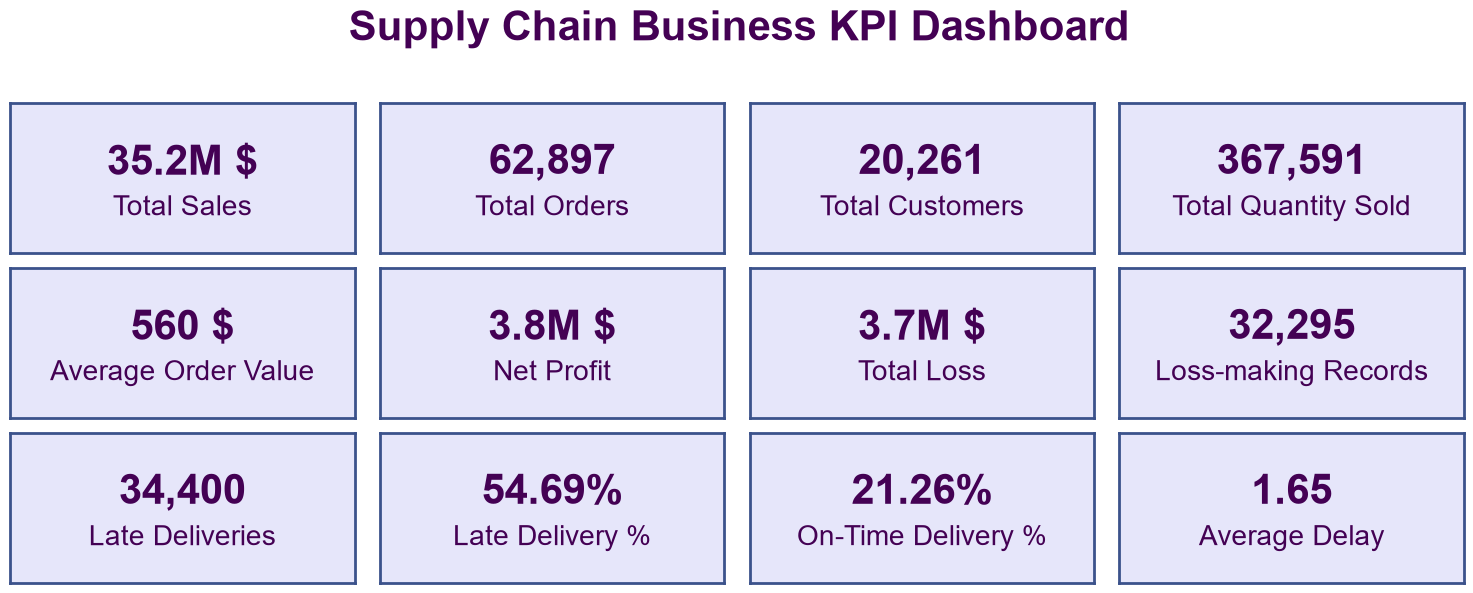

In [146]:
# Select KPIs for dashboard

display_metrics = [
    ('Total Sales', metrics['Total Sales']),
    ('Total Orders', metrics['Total Orders']),
    ('Total Customers', metrics['Total Customers']),
    ('Total Quantity Sold', metrics['Total Quantity Sold']),

    ('Average Order Value', metrics['Average Order Value']),
    ('Net Profit', metrics['Net Profit']),
    ('Total Loss', metrics['Total Loss']),
    ('Loss-making Records', metrics['Loss-making Records']),

    ('Late Deliveries', metrics['Late Deliveries']),
    ('Late Delivery %', metrics['Late Delivery %']),
    ('On-Time Delivery %', metrics['On-Time Delivery %']),
    ('Average Delay', metrics['Average Delay (Days)'])
]
# 2. Create KPI cards

fig, axes = plt.subplots(3, 4, figsize=(15, 6))

axes = axes.flatten()

for ax, (title, value) in zip(axes, display_metrics):

    # KPI value
    ax.text(
        0.5, 0.60, value,
        ha='center',
        va='center',
        fontsize=30,
        fontweight='bold',
        color=primary_color
    )

    # KPI title
    ax.text(
        0.5, 0.30, title,
        ha='center',
        va='center',
        fontsize=20,
        color=primary_color
    )

    # Card background
    ax.set_facecolor('Lavender')

    ax.set_xticks([])
    ax.set_yticks([])

    # Card border
    for spine in ax.spines.values():
        spine.set_color(secondary_color)
        spine.set_linewidth(2)


# Hide the unused eighth card
for ax in axes[len(display_metrics):]:
    ax.set_visible(False)


# 3. Dashboard background and title

fig.patch.set_facecolor('white')

plt.suptitle(
    'Supply Chain Business KPI Dashboard',
    fontsize=30,
    fontweight='bold',
    color=primary_color
)

plt.tight_layout(rect=[0, 0, 1, 0.94])

plt.show()

**Observation:**

1. **Sales & Revenue Metrics**

* Total Sales: $35.2 Million
* Net Profit: $3.8 Million
* Total Loss: $3.7 Million
* Profit and loss values are nearly equal in magnitude.

2. **Customer & Order Metrics**

* Total Orders: 62,897
* Total Customers: 20,261
* * Total Quantity Sold: 367,591 units
* Average Order Value (AOV): $560

3. **Delivery Performance Metrics**

* Late Deliveries: 34,400
* Late Delivery Rate: 54.69%
* On-Time Delivery Rate: 21.26%
* Average Delay: 1.65 days

**Risk Indicators**

* More than half of all deliveries are delayed.
* The number of loss-making transactions is extremely high (32,295 records).

**Business Insight:**

1. **Revenue & Profitability**

* Despite generating $35.2M in sales, profitability remains constrained by substantial losses.

* The proximity between total profit and total loss indicates operational inefficiencies.

* Margin improvement initiatives should focus on:
    - Reducing shipping costs.
    - Optimising pricing.
    - Minimising discount leakage.

3. **Customer Behaviour**

* The business serves a large customer base with over 20,000 customers.

* AOV of $560 indicates relatively high-value purchases.

* Upselling and cross-selling programmes could further increase order value.

4. **Logistics & Supply Chain Performance**

* A 54.69% late-delivery rate is a critical operational issue.

* Late deliveries may directly impact:
    - Customer satisfaction.
    - Repeat purchases.
    - Brand loyalty.

* Reducing average delay from 1.65 days could significantly improve customer experience.

5. **Operational Efficiency**

* More than 32,000 loss-making transactions suggest the presence of:
    - Unprofitable products.
    - High shipping costs.
    - Misaligned discount strategies.
    - Inefficient inventory management.
*  Profitability analysis should be performed at:
    - Product level.
    - Category level.
    - Regional level.

# 1. INVENTORY MANAGEMENT 

Inventory management focuses on understanding how products move through the supply chain based on customer orders and product demand.

The purpose of this analysis is to:

- Identify high-demand and low-demand products.
- Identify fast-moving and slow-moving products.
- Analyze product demand across different categories.
- Understand which products contribute the most to sales.
- Identify products and categories that may require greater inventory planning attention.
- Analyze product demand across different markets.

**Business Problem** 
To identify product demand patterns across different categories, markets, regions and time periods to support better demand planning and inventory management.

## 1.1 Product-Level Demand Analysis

### Which products have the highest demand?

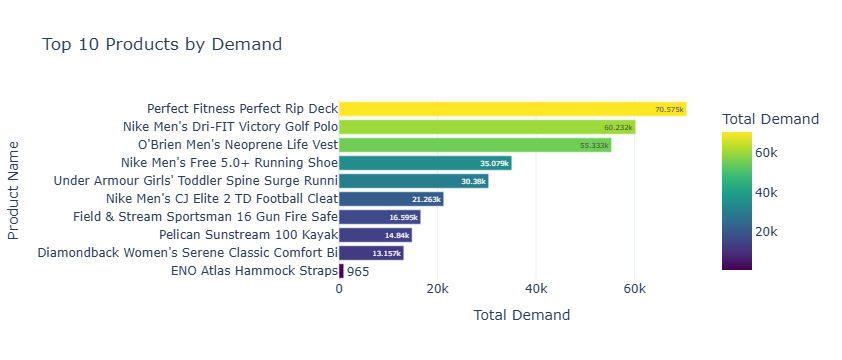

In [123]:
product_demand = (
    df.groupby('Product Name')['Order Item Quantity']
    .sum()
    .reset_index(name='Total Demand')
    .sort_values('Total Demand', ascending=False)
)

product_demand.head(10)

fig = px.bar(
    product_demand.head(10),
    x='Total Demand',
    y='Product Name',
    orientation='h',
    color='Total Demand',
    color_continuous_scale='Viridis',
    title='Top 10 Products by Demand',
    text_auto=True
)

fig.update_layout(
    template='plotly_white',
    yaxis={'categoryorder': 'total ascending'}
)

fig.show()

**Observation:**

* Perfect Fitness Perfect Rip Deck has the highest demand at approximately 76.6k units, significantly outperforming all other products.

* Nike Men's Dri-FIT Victory Golf Polo and O'Brien Men's Neoprene Life Vest are the second and third most demanded products with around 60k and 53k units respectively.

* Demand drops gradually from the top three products to the middle-ranked products.

* A large gap exists between the highest-demand product (76.6k) and the lowest product in the top 10 list (ENO Atlas Hammock Straps at less than 1k units).

* Sportswear, fitness, and outdoor recreation products dominate the list.

* The top 5 products contribute a disproportionately large share of total demand, indicating a skewed demand distribution.

**Business Insight:**

* The Perfect Rip Deck should be prioritised for inventory planning and replenishment to avoid stockouts.

* High-performing products can be leveraged for:
    * Cross-selling opportunities.
    * Promotional bundles.
    * Premium pricing strategies if demand remains strong.
* Nike products appear multiple times in the top-demand list, suggesting strong brand preference among customers.
* Low-demand products in the Top 10 may still require review to determine whether inventory levels are justified.
* Focus marketing budgets on proven high-demand products while analysing why certain products underperform.

### Which products have the lowest demand?

In [124]:
print(product_demand.columns)

Index(['Product Name', 'Total Demand'], dtype='str')


In [125]:
low_demand = (
    df.groupby('Product Name')['Order Item Quantity']
    .sum()
    .reset_index(name='Total Demand')
    .sort_values('Total Demand', ascending=True)
)

print(low_demand.head(10).to_string(float_format='{:,.2f}'.format))

                                     Product Name  Total Demand
9          Bushnell Pro X7 Jolt Slope Rangefinder             8
4               Bowflex SelectTech 1090 Dumbbells            10
76                            SOLE E25 Elliptical            10
77                            SOLE E35 Elliptical            15
80  Stiga Master Series ST3100 Competition Indoor            25
20  Diamondback Girls' Clarity 24 Hybrid Bike 201            26
19  Diamondback Boys' Insight 24 Performance Hybr            28
29              Garmin Approach S4 Golf GPS Watch            31
36              GoPro HERO3+ Black Edition Camera            32
93               Titleist Club Glove Travel Cover            33


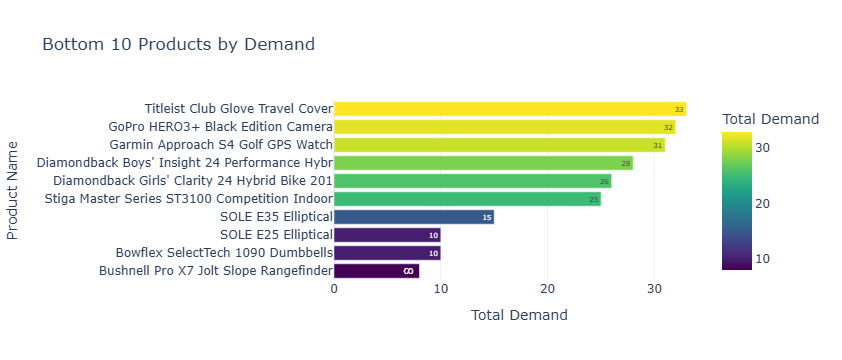

In [126]:
fig = px.bar(
    low_demand.head(10),
    x='Total Demand',
    y='Product Name',
    orientation='h',
    color='Total Demand',
    color_continuous_scale='Viridis',
    title='Bottom 10 Products by Demand',
    text_auto=True
)

fig.update_layout(
    template='plotly_white',
    yaxis={'categoryorder': 'total ascending'}
)

fig.show()

**Observation:**

* The least demanded product is Bushnell Pro X7 Jolt Slope Rangefinder with only 8 units sold.

* Bowflex SelectTech 1090 Dumbbells and SOLE E25 Elliptical recorded approximately 10 units each.

* Demand for all bottom 10 products ranges from 8 to 33 units, which is extremely low compared to top-selling products (which reached over 70,000 units).

* Several low-demand products belong to high-value categories such as:
    * Electronics (GoPro Camera, Garmin GPS Watch)
    * Fitness Equipment (SOLE Ellipticals, Bowflex Dumbbells)
    * Bicycles (Diamondback Bikes)

* The demand gap between top-selling and bottom-selling products is enormous, indicating a highly skewed product portfolio.

**Business Insight:**

* These products may be experiencing:
    * Poor market fit.
    * High pricing barriers.
    * Limited customer awareness.
    * Seasonal or niche demand.

* Conduct profitability analysis before discontinuing them, as some low-volume products may have high margins.
* Consider:
    * Bundle offers.
    * Promotional campaigns.
    * Targeted advertising.
    * Product repositioning.

* Review inventory levels to minimise holding and warehousing costs.

* Products with consistently low demand could be candidates for liquidation or replacement.

## 1.2 Category-Level Inventory Demand

### Which product categories have the highest demand?

In [36]:
category_demand = (
    df.groupby('Category Name')
    .agg(
        Total_Quantity=('Order Item Quantity', 'sum'),
        Total_Orders=('Order Id', 'nunique'),
        Total_Sales=('Order Item Total', 'sum')
    )
    .reset_index()
    .sort_values('Total_Quantity', ascending=False)
)

print(category_demand.head(10).to_string(float_format='{:,.2f}'.format))

           Category Name  Total_Quantity  Total_Orders  Total_Sales
12                Cleats           70611         19534 3,815,653.41
47       Women's Apparel           60232         17088 2,706,768.50
30  Indoor/Outdoor Games           55333         15912 2,485,575.58
10      Cardio Equipment           35937         10857 3,174,909.16
38         Shop By Sport           31329          9700 1,126,786.16
34        Men's Footwear           21263         17954 2,483,852.70
18               Fishing           16595         14527 5,964,765.44
46          Water Sports           14880         13174 2,679,256.78
9       Camping & Hiking           13157         11787 3,546,428.27
17           Electronics            9061          2931   320,547.09


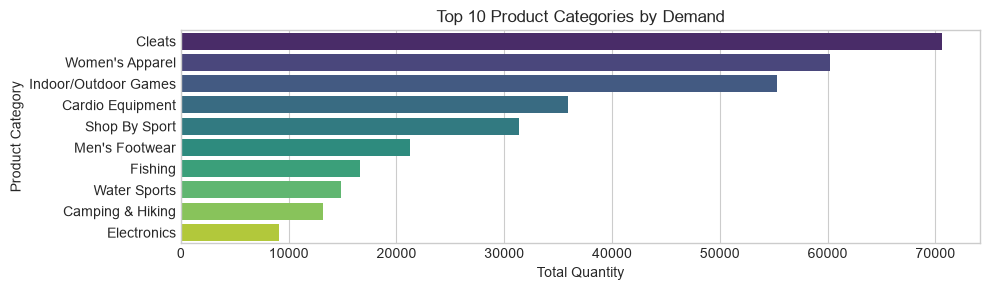

In [37]:
plt.figure(figsize=(10,3))

sns.barplot(
    data=category_demand.head(10),
    x='Total_Quantity',
    y='Category Name',
    hue='Category Name',
    palette='viridis',
    legend=False
)

plt.title('Top 10 Product Categories by Demand')
plt.xlabel('Total Quantity')
plt.ylabel('Product Category')

plt.tight_layout()
plt.show()

**Observation:**

* Cleats is the highest-demand category with approximately 70k units.

* Women's Apparel follows with around 60k units.

* Indoor/Outdoor Games ranks third at around 55k units.

* Demand significantly decreases after the top three categories.

* Outdoor and sports-related categories dominate demand.

* Electronics show the lowest demand among the top 10 categories.

* The distribution demonstrates a concentration of demand in a few categories.

**Business Insight:**

* Cleats and Women's Apparel should receive:
    * Priority inventory allocation.
    * Larger marketing budgets.
    * Stronger supplier relationships.

* The popularity of sports categories suggests customers primarily view the retailer as a sports and outdoor equipment provider.
    * Electronics may require:
    * Better promotion.
    * Category optimisation.
    * Product assortment review.

* High-performing categories can be used to introduce related products through targeted recommendations.

* Category-level demand concentration indicates that revenue growth can be accelerated by expanding successful sports-related product lines.

### Which categories generate the highest revenue?

In [30]:
category_revenue = (
    df.groupby('Category Name')['Order Item Total']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
print(category_revenue.head(10).to_string(float_format='{:,.2f}'.format))

          Category Name  Order Item Total
0               Fishing      5,964,765.44
1                Cleats      3,815,653.41
2      Camping & Hiking      3,546,428.27
3      Cardio Equipment      3,174,909.16
4       Women's Apparel      2,706,768.50
5          Water Sports      2,679,256.78
6  Indoor/Outdoor Games      2,485,575.58
7        Men's Footwear      2,483,852.70
8         Shop By Sport      1,126,786.16
9             Computers        572,527.50


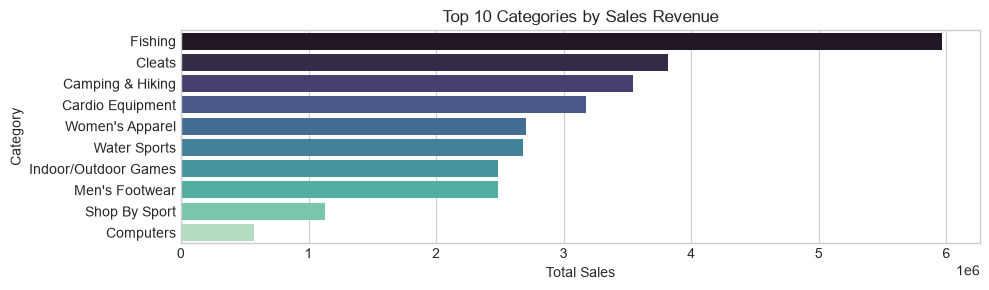

In [34]:
plt.figure(figsize=(10,3))

sns.barplot(
    data=category_revenue.head(10),
    x='Order Item Total',
    y='Category Name',
    hue='Category Name',
    palette='mako',
    legend=False
)

plt.title('Top 10 Categories by Sales Revenue')
plt.xlabel('Total Sales')
plt.ylabel('Category')

plt.tight_layout()
plt.show()

**Observation:**

* Fishing generates the highest revenue, approximately $6 million.

* Cleats ranks second with nearly $3.8 million in revenue.

* Camping & Hiking generates roughly $3.5 million.

* Cardio Equipment and Women's Apparel contribute over $3 million each.

* Some categories that have moderate demand create high revenue, suggesting higher-priced products.

* Computers appears among the top revenue-generating categories despite not appearing among the highest-demand categories.

**Business Insight:**

* Revenue and demand are not perfectly correlated.

* High-volume categories drive demand.

* High-value categories drive revenue.

* Fishing products likely command higher average selling prices or margins.

* Computers and specialised equipment may represent premium-priced products with lower sales volumes.

* Business strategy should classify categories into:

* High Demand + High Revenue (Cleats, Women's Apparel)

* Low Demand + High Revenue (Fishing, Computers)

* High Demand + Moderate Revenue (Indoor/Outdoor Games)

* Premium categories should receive targeted marketing because even small sales increases can generate substantial revenue.

* Revenue optimisation should focus not only on sales volume but also on product mix and pricing strategy.

## 1.3 Fast-Moving and Slow-Moving Product Analysis

- Fast-moving products: Products with relatively high demand.
- Medium-moving products: Products with moderate demand.
- Slow-moving products: Products with relatively low demand.

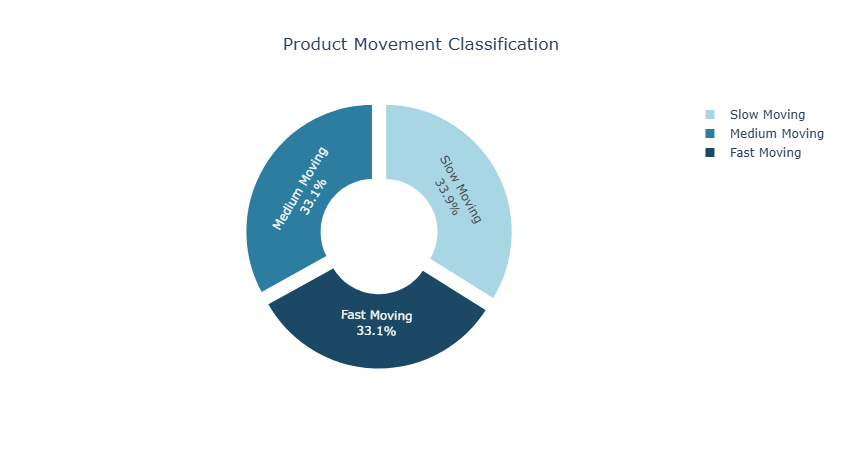

In [19]:
product_movement = (
    df.groupby('Product Name')
    .agg(
        Total_Quantity=('Order Item Quantity', 'sum'),
        Total_Orders=('Order Id', 'nunique'),
        Total_Sales=('Sales', 'sum')
    )
    .reset_index()
)

product_movement['Movement_Score'] = (
    product_movement['Total_Quantity']
)

product_movement['Movement_Category'] = pd.qcut(
    product_movement['Movement_Score'].rank(method='first'),
    q=3,
    labels=['Slow Moving', 'Medium Moving', 'Fast Moving']
)
movement_count = (
    product_movement['Movement_Category']
    .value_counts()
    .reset_index()
)

movement_count.columns = ['Movement Category', 'Product Count']

fig = px.pie(
    movement_count,
    names='Movement Category',
    values='Product Count',
    hole=0.4,
    title='Product Movement Classification',
    color='Movement Category',
    color_discrete_map={
        'Slow Moving': '#A9D6E5',
        'Medium Moving': '#2C7DA0',
        'Fast Moving': '#1B4965'
    }
)

fig.update_traces(
    pull=[0.05, 0.05, 0.05],
    marker=dict(line=dict(color='white', width=3)),
    textinfo='label+percent',
    textposition='inside'
)

fig.update_layout(
    title=dict(x=0.5, xanchor='center'),
    template='plotly_white',
    height=450,
    width=650
)

fig.show()

**Observation:**

Among the 118 products analysed:

* Fast-moving products: 33.1%

* Medium-moving products: 33.1%

* Slow-moving products: 33.9%

The distribution indicates that products are almost equally distributed across all three movement categories, with slow-moving products having a slightly higher share.

**Business Insight:**

* Inventory balance: Product movement is relatively evenly distributed, indicating that the business has different levels of product demand across its product portfolio.

* Slow-moving inventory: The slightly higher percentage of slow-moving products (33.9%) may indicate a risk of excess inventory, increased storage costs and tied-up working capital.

* Fast-moving products: Fast-moving products (33.1%) require regular stock monitoring and timely replenishment to avoid stockouts and missed sales opportunities.

* Inventory optimization: The business should review stock levels and adjust purchasing strategies according to product movement patterns.

| Product Classification | Business Action |
|---|---|
| Fast Moving | Prioritize replenishment and maintain sufficient stock |
| Medium Moving | Monitor demand and maintain balanced inventory |
| Slow Moving | Review purchasing quantities and avoid excess inventory |


## 1.4 Product Demand Across Different Markets

Understand how product demand differs geographically.

**Business Questions:**

- Which markets generate the highest product demand?
- Which markets have relatively lower demand?
- How is demand distributed across geographical markets?

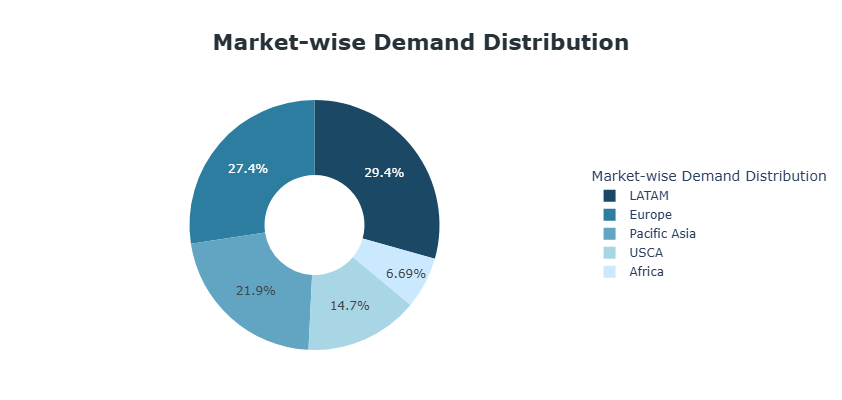

In [132]:
market_demand = (
    df.groupby('Market')['Order Item Quantity']
    .sum()
    .reset_index(name='Total Demand')
    .sort_values('Total Demand', ascending=False)
)

market_demand

fig = px.pie(
    market_demand,
    names='Market',
    values='Total Demand',
    hole=0.4,
    title='Market-wise Demand Distribution',
    color_discrete_sequence=SALES_PALETTE
)

fig.update_layout(
    title=dict(
        text='<b>Market-wise Demand Distribution</b>',
        x=0.5,
        xanchor='center',
        font=dict(size=22, color='#263238')
    ),
    legend=dict(
        title='Market-wise Demand Distribution',
        orientation='v',
        x=1.02,
        y=0.5
    ),
    width=700,
    height=400,
    margin=dict(l=50, r=180, t=100, b=50)
    
)

fig.show()

**Observation:**

* LATAM contributes the highest share of demand at approximately 29.4%.
* Europe follows closely with around 27.4% of total demand.
* Pacific Asia accounts for approximately 21.9%.
* USCA contributes about 14.7%.
* Africa has the smallest market share at approximately 6.7%.
* LATAM and Europe together contribute nearly 57% of overall demand.
* Demand distribution is concentrated in three major markets: LATAM, Europe, and Pacific Asia.

**Business Insight:**

* LATAM and Europe should be considered strategic growth markets due to their dominant contribution.
* Strong demand in these regions justifies:
* Higher inventory allocation.
* Additional distribution centres.
* Localised marketing campaigns.
* Africa presents a growth opportunity but may require:
* Market penetration strategies.
* Improved logistics networks.
* Competitive pricing models.
* Pacific Asia's strong contribution suggests expansion opportunities in rapidly growing economies.
* Resource allocation should be market-specific, prioritising high-demand regions while developing underperforming markets.


### 1.5 Region-wise Demand Analysis

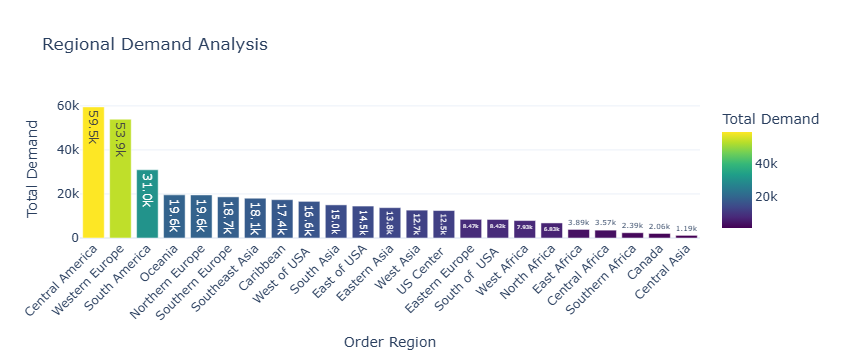

In [133]:
region_demand = (
    df.groupby('Order Region')['Order Item Quantity']
    .sum()
    .reset_index(name='Total Demand')
    .sort_values('Total Demand', ascending=False)
)
fig = px.bar(
    region_demand,
    x='Order Region',
    y='Total Demand',
    color='Total Demand',
    color_continuous_scale='Viridis',
    title='Regional Demand Analysis',
    text_auto='.3s'
)

fig.update_layout(
    template='plotly_white',
    xaxis_tickangle=-45
)

fig.show()

**Observation:**

* Central America records the highest demand with approximately 59.5k units.
* Western Europe follows closely at about 53.9k units.
* South America is the third-largest market with roughly 31k units.
* Demand is highly uneven across regions.
* Several regions cluster around 13k–20k units demand:
* Oceania
* Northern Europe
* Southern Europe
* Southeast Asia
* Caribbean
* Western USA
* African regions generally report lower demand levels.
* Central Asia records the lowest demand at approximately 1.2k units.

**Business Insight:**

* Central America and Western Europe should be treated as strategic regions due to their significant contribution to total demand.
* High-demand regions offer opportunities for:
    * Market expansion.
    * New product launches.
    * Regional fulfilment centres.
* Low-demand regions such as Central Asia and parts of Africa require market assessment to identify barriers such as:
    * Limited distribution networks.
    * Low brand awareness.
    * Economic constraints.
* Regional demand variation suggests that localisation strategies may improve sales performance.
* Marketing investments should be prioritised based on regional demand potential and profitability.

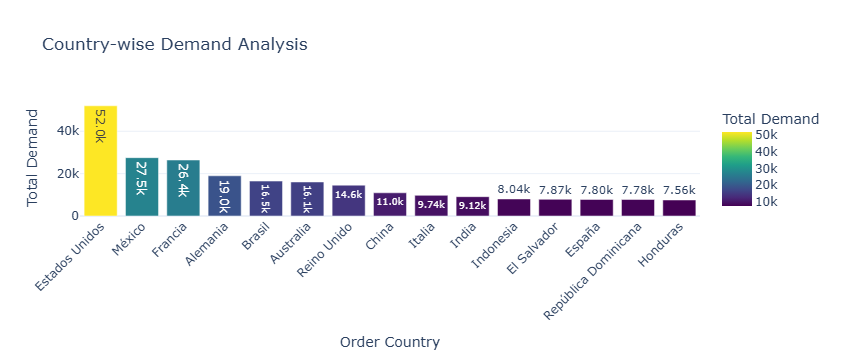

In [23]:
country_demand = (
    df.groupby('Order Country')['Order Item Quantity']
    .sum()
    .reset_index(name='Total Demand')
    .sort_values('Total Demand', ascending=False)
)
fig = px.bar(
    country_demand.head(15),
    x='Order Country',
    y='Total Demand',
    color='Total Demand',
    color_continuous_scale='Viridis',
    title='Country-wise Demand Analysis',
    text_auto='.3s'
)

fig.update_layout(
    template='plotly_white',
    xaxis_tickangle=-45
)

fig.show()

**Observation:**

* United States is the largest market with sales exceeding 4.5M, significantly outperforming all other countries.

* France and Mexico are the second and third highest contributors, generating around 2.5M-2.8M in sales.

* There is a substantial gap between the United States and the rest of the countries.

* Countries such as Germany, Australia, United Kingdom, and Brazil form a strong middle tier.

* Countries including El Salvador, Honduras, and Dominican Republic contribute relatively lower sales volumes.

**Business Insight:**

* The company is highly dependent on the United States market, creating both a growth opportunity and a concentration risk.

* France and Mexico represent mature international markets and may offer strong opportunities for deeper market penetration.

* Mid-tier markets such as Germany, Australia, UK, Brazil, and China have potential for targeted marketing and expansion initiatives.

* Lower-performing countries may require localised marketing strategies, partner networks, or product adjustments to increase market adoption.

* Diversifying revenue across more countries can reduce reliance on the United States and improve long-term business resilience.

# 2. LOGISTICS OPTIMIZATION

Logistics optimization focuses on understanding the efficiency of product transportation and delivery.

The purpose is to identify delivery delays, evaluate shipping methods and understand geographical differences in delivery performance.

**Business Problem** 
To evaluate delivery performance across shipping modes, geographical regions and markets to identify logistics inefficiencies and opportunities for improving delivery reliability.

### 2.1 Overall Delivery Performance

**Business Questions:**

- What percentage of shipments are delivered late?
- What percentage are delivered on time?
- What percentage are delivered earlier than scheduled?

In [134]:
#Delivery Status Distribution
delivery_distribution = df['Delivery Status'].value_counts()

print(delivery_distribution)

#Calculate percentage distribution
delivery_percentage = (
    df['Delivery Status'].value_counts(normalize=True) * 100
)

delivery_percentage.round(2)

Delivery Status
Late Delivery        94523
Advanced Shipping    41592
Shipping On Time     36650
Name: count, dtype: int64


Delivery Status
Late Delivery        54.71
Advanced Shipping    24.07
Shipping On Time     21.21
Name: proportion, dtype: float64

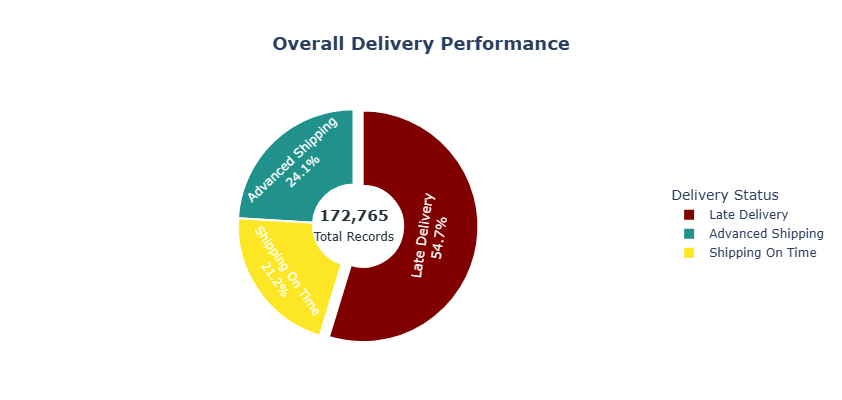

In [135]:
delivery_distribution = (
    df['Delivery Status']
    .value_counts()
    .reset_index()
)

delivery_distribution.columns = ['Delivery Status', 'Count']

delivery_distribution['Percentage'] = (
    delivery_distribution['Count'] /
    delivery_distribution['Count'].sum() * 100
)
fig = px.pie(
    delivery_distribution,
    names='Delivery Status',
    values='Count',
    hole=0.35,
    color='Delivery Status',
    color_discrete_map={
        'Advanced Shipping': '#21918C',
        'Shipping On Time': '#FDE725',
        'Late Delivery': '#800000'
    },
    title='Overall Delivery Performance'
)

fig.update_traces(
    textposition='inside',
    textinfo='label+percent',
    textfont=dict(size=13, color='white'),
    marker=dict(
        line=dict(color='white', width=2)
    ),
    pull=[
        0.08 if status == 'Late Delivery' else 0
        for status in delivery_distribution['Delivery Status']
    ],
    hovertemplate=(
        '<b>%{label}</b><br>'
        'Records: %{value:,}<br>'
        'Percentage: %{percent}<extra></extra>'
    )
)

# Add total records in the centre
total_records = delivery_distribution['Count'].sum()

fig.add_annotation(
    text=f'<b>{total_records:,}</b><br><span style="font-size:12px">Total Records</span>',
    x=0.5,
    y=0.5,
    showarrow=False,
    font=dict(size=15, color='#263238')
)

fig.update_layout(
    title=dict(
        text='<b>Overall Delivery Performance</b>',
        x=0.5,
        xanchor='center',
        font=dict(size=18)
    ),
    legend=dict(
        title='Delivery Status',
        orientation='v',
        y=0.5,
        x=1.02
    ),
    width=700,
    height=400,
    margin=dict(l=50, r=180, t=100, b=50),
    paper_bgcolor='white',
    plot_bgcolor='white'
)

fig.show()

**Observation:**

* Late Delivery accounts for the majority of orders at 54.7%.

* Advanced Shipping represents 24.1% of deliveries.

* Shipping On Time accounts for only 21.2% of deliveries.

* More than half of all deliveries fail to meet the expected delivery schedule.

* Total records analysed: 172,765 orders.

**Business Insight:**

* The delivery performance is a major operational concern, with late deliveries affecting more than half of all customer orders.

* Such a high delay rate can negatively impact customer satisfaction, retention, brand reputation, and repeat purchases.

* The company may face increased support costs, refund requests, or compensation claims due to delivery issues.

* Logistics operations, warehouse efficiency, courier partnerships, and demand forecasting should be reviewed to identify bottlenecks causing delays.

* Improving on-time delivery rates even by a small percentage could lead to significant improvements in customer experience and long-term revenue.

### 2.2 Shipping Mode Performance Analysis

**Business Questions:**

- Which shipping mode experiences the highest delivery delays?
- Which shipping mode has better delivery performance?
- Are faster shipping modes consistently delivering on time?


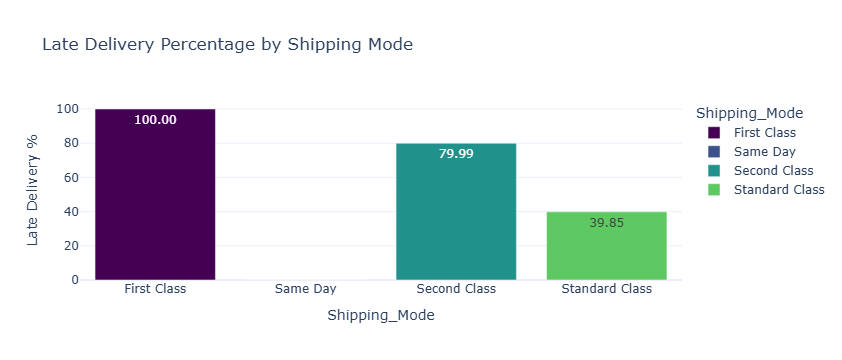

In [28]:
shipping_analysis = (
    df.groupby('Shipping Mode')
    .agg(
        Total_Shipments=('Order Id', 'nunique'),
        Average_Scheduled_Days=('Scheduled Shipping days', 'mean'),
        Average_Actual_Days=('Actual Shipping Days', 'mean'),
        Late_Deliveries=('Is delay', 'sum')
    )
    .reset_index()
)

shipping_analysis['Late Delivery %'] = (
    shipping_analysis['Late_Deliveries'] /
    shipping_analysis['Total_Shipments']
) * 100
order_level = (
    df.groupby('Order Id')
    .agg(
        Shipping_Mode=('Shipping Mode', 'first'),
        Scheduled_Days=('Scheduled Shipping days', 'first'),
        Actual_Days=('Actual Shipping Days', 'first'),
        Is_Delay=('Is delay', 'max')
    )
    .reset_index()
)

shipping_analysis = (
    order_level.groupby('Shipping_Mode')
    .agg(
        Total_Orders=('Order Id', 'nunique'),
        Average_Scheduled_Days=('Scheduled_Days', 'mean'),
        Average_Actual_Days=('Actual_Days', 'mean'),
        Late_Deliveries=('Is_Delay', 'sum')
    )
    .reset_index()
)

shipping_analysis['Late Delivery %'] = (
    shipping_analysis['Late_Deliveries'] /
    shipping_analysis['Total_Orders']
) * 100

fig = px.bar(
    shipping_analysis,
    x='Shipping_Mode',
    y='Late Delivery %',
    color='Shipping_Mode',    
    template='plotly_white',
    title='Late Delivery Percentage by Shipping Mode',
    text_auto='.2f',
    color_discrete_sequence=custom_palette
)

fig.show()



**Observation:**

* First Class shipping shows a 100% late delivery rate, making it the worst-performing shipping mode.

* Second Class shipping has a very high late delivery rate of approximately 80%.

* Standard Class shipping performs significantly better, with a late delivery rate of around 40%.

* Same Day shipping has no visible bar, suggesting either insufficient data or negligible late deliveries.

* Premium shipping options are surprisingly experiencing higher delays than slower shipping services.

**Business Insight:**

* Customers paying premium shipping fees are not receiving the expected service levels, creating a major risk to customer satisfaction and brand reputation.

* First Class and Second Class logistics contracts should be audited immediately to identify carrier performance issues.

* The high delay rates in premium modes may result in refund requests, negative reviews, and customer churn.

* Standard Class appears to be the most reliable option and may currently provide the best balance between cost and performance.

* Operations teams should prioritise improving premium shipping reliability before increasing marketing or pricing for these services.

* Service-level agreements (SLAs) with logistics partners should be reviewed and enforced to reduce late deliveries.

### 2.3 Scheduled vs Actual Shipping Days

**Business Questions:**

- Are shipments taking longer than scheduled?
- How frequently are shipments delivered earlier than expected?
- Which shipping modes have the largest difference between scheduled and actual delivery time?

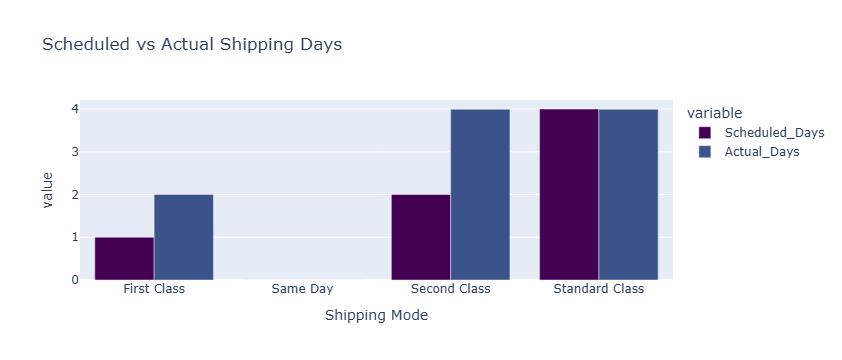

In [137]:
shipping_comparison = (
    df.groupby('Shipping Mode')
    .agg(
        Scheduled_Days=('Scheduled Shipping days', 'mean'),
        Actual_Days=('Actual Shipping Days', 'mean')
    )
    .reset_index()
)

shipping_comparison['Difference'] = (
    shipping_comparison['Actual_Days'] -
    shipping_comparison['Scheduled_Days']
)

shipping_comparison
fig = px.bar(
    shipping_comparison,
    x='Shipping Mode',
    y=['Scheduled_Days', 'Actual_Days'],
    barmode='group',
    title='Scheduled vs Actual Shipping Days',
    color_discrete_sequence=custom_palette
)

fig.show()

**Observation:**

* First Class shipping is scheduled for 1 day but actually takes 2 days, indicating a 1-day delivery delay.
* Second Class shipping is scheduled for 2 days but takes 4 days, showing the largest delay (2 days).
* Standard Class shipping meets its promised timeline, with both scheduled and actual delivery taking 4 days.
* Same Day shipping data appears unavailable or negligible in the chart.
* Delivery performance varies significantly by shipping mode.
* Premium shipping options (First Class and Second Class) show service-level gaps.

**Business Insight:**

* The largest operational concern is Second Class shipping, where actual delivery time is double the scheduled duration.
* Customers paying for faster shipping may experience dissatisfaction due to delivery delays.
vStandard Class appears to be the most reliable shipping method in terms of expectation vs reality.
* Logistics teams should investigate:
    * Carrier performance
    * Warehouse processing times
    * Regional delivery bottlenecks
* Improving First Class and Second Class fulfilment could directly enhance customer satisfaction and retention.
* Delay analysis should be incorporated into SLA (Service Level Agreement) monitoring.

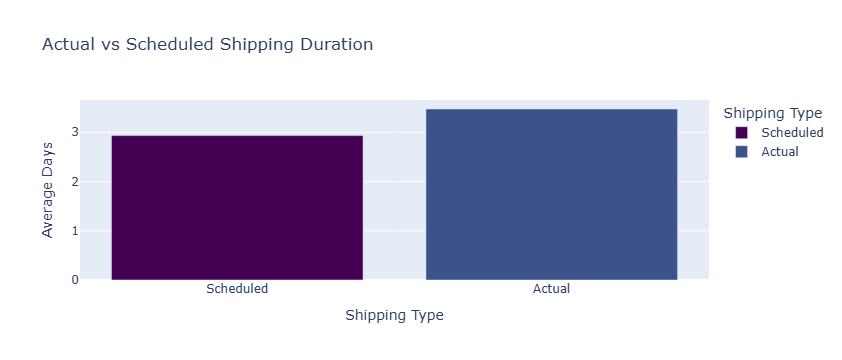

In [5]:
shipping_days = pd.DataFrame({
    'Shipping Type': ['Scheduled', 'Actual'],
    'Average Days': [
        df['Scheduled Shipping days'].mean(),
        df['Actual Shipping Days'].mean()
    ]
})

fig = px.bar(
    shipping_days,
    x='Shipping Type',
    y='Average Days',
    color='Shipping Type',
    title='Actual vs Scheduled Shipping Duration',
    color_discrete_sequence=custom_palette
)

fig.show()

**Observation:**

* The average scheduled shipping duration is approximately 2.9 days, while the actual shipping duration is around 3.5 days.

* Actual deliveries take roughly 0.5–0.6 days longer than planned.

* The gap between scheduled and actual duration indicates a consistent delay across the supply chain rather than isolated incidents.

* The difference represents nearly 18–20% higher delivery time than originally promised.

**Business Insight:**

* The company is systematically underestimating delivery times, which can negatively impact customer satisfaction and trust.

* Current delivery commitments may not accurately reflect operational realities, leading to increased customer complaints and support requests.

* Management should investigate bottlenecks such as warehouse processing, carrier performance, customs delays, or last-mile delivery issues.

* Revising estimated delivery times based on historical performance can improve promise accuracy and customer experience.

* Predictive logistics models could help forecast delays and provide more realistic delivery commitments.

### 2.4 Regional Delivery Performance

**Business Questions:**

- Which regions experience the highest delivery delays?
- Which regions have better delivery performance?
- Are certain geographical areas more challenging for logistics operations?

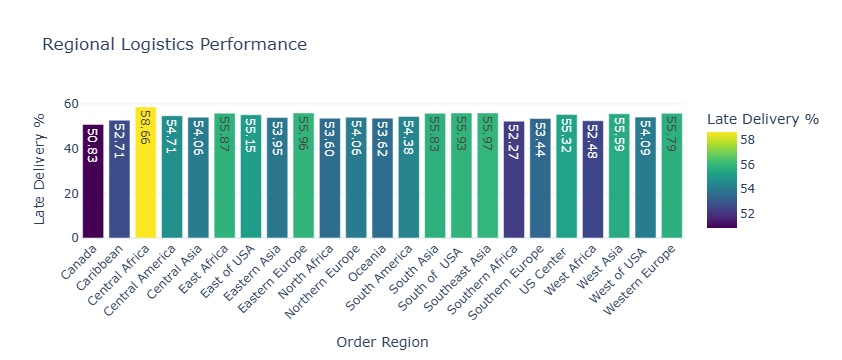

In [138]:
regional_logistics = (
    df.groupby('Order Region')
    .agg(
        Total_Records=('Order Id', 'count'),
        Late_Deliveries=('Is delay', 'sum'),
        Average_Delivery_Days=('Actual Shipping Days', 'mean')
    )
    .reset_index()
)

regional_logistics['Late Delivery %'] = (
    regional_logistics['Late_Deliveries'] /
    regional_logistics['Total_Records']
) * 100
fig = px.bar(
    regional_logistics,
    x='Order Region',
    y='Late Delivery %',
    color='Late Delivery %',
    color_continuous_scale='Viridis',
    title='Regional Logistics Performance',
    text_auto='.2f'
)

fig.update_layout(
    template='plotly_white',
    xaxis_tickangle=-45
)

fig.show()

**Observation:**

* Central Asia (~0.62) exhibits the highest delivery variance, indicating the least predictable delivery performance.

* Central Africa (~0.61) and South of USA (~0.59) also show high variability.

* The lowest delivery variance is observed in Canada (~0.42) and Southern Africa (~0.43).

* Most regions fall within a narrow range of 0.50–0.58, suggesting moderate consistency across the global network.

* European regions generally demonstrate relatively stable performance with variance levels around 0.48–0.57.

**Business Insight:**

* High variance is often more damaging than high average delay because it reduces delivery predictability and customer confidence.

* Regions such as Central Asia and Central Africa require deeper analysis of carrier reliability, customs processing, and transportation bottlenecks.

* Stable regions like Canada and Southern Africa can serve as operational benchmarks for best practices.

* Businesses should implement dynamic ETA prediction models in regions with high variance to improve delivery accuracy.

* Reducing variability can improve customer satisfaction even if average delivery times remain unchanged.

### 2.5 Delivery Risk Analysis

**Business Questions:**

- How does delivery risk vary across shipping modes?
- Are high-risk orders more likely to experience late delivery?
- Which shipping modes have a higher proportion of risky shipments?

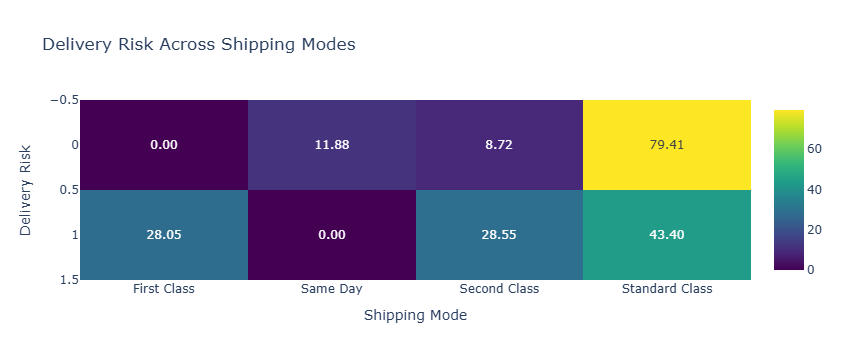

In [139]:
risk_analysis = pd.crosstab(
    df['Delivery Risk'],
    df['Shipping Mode'],
    normalize='index'
) * 100

risk_analysis

fig = px.imshow(
    risk_analysis,
    text_auto='.2f',
    aspect='auto',
    color_continuous_scale='Viridis',
    title='Delivery Risk Across Shipping Modes'
)

fig.show()

**Observation:**

* Standard Class exhibits the highest delivery risk concentration, with risk metrics reaching approximately 79.41.
* Standard Class also demonstrates significant delayed-delivery records (43.40 in the delayed category).
* First Class shows moderate delivery risk levels (approximately 28.05 delayed-risk score).
* Second Class presents a similar risk profile (approximately 28.55 delayed-risk score).
* Same Day shipping shows the lowest delivery risk among the available shipping options.
* Delivery risk is not uniformly distributed across shipping modes.

**Business Insight:**

* Standard Class shipping requires immediate operational attention because it represents the largest delivery-risk exposure.
* Delays in Standard Class impact a large customer base due to its widespread usage.
* Logistics teams should analyse:
    * Warehouse processing delays.
    * Carrier performance.
    * Regional bottlenecks.
    * Last-mile delivery issues.
* Same Day shipping processes can serve as a benchmark for improving other shipping methods.
* Delivery-risk monitoring should become a key operational KPI to improve customer satisfaction and reduce service failures.

# 3.DEMAND ANALYSIS

Demand analysis focuses on understanding customer purchasing behaviour and identifying historical demand patterns.

It helps businesses understand:

- How demand changes over time.
- Which months generate higher demand.
- Which product categories are popular.
- Which geographical markets generate more orders.
- Which customer segments contribute to demand.
- How product demand changes across different years.

### 3.1 Monthly Demand Analysis

**Business Question:**
- How does product demand change every month?
- Are there seasonal demand patterns?
- Which months experience higher and lower demand?

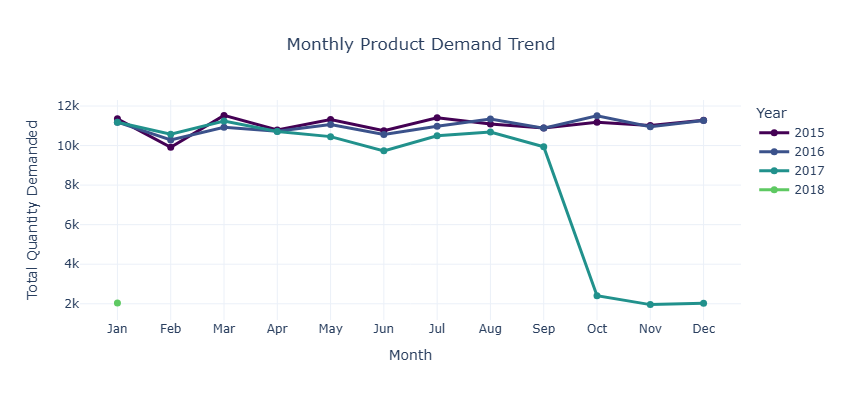

In [140]:
monthly_demand = (df.groupby(['Order Year', 'Order Month', 'Month_Name'])
    ['Order Item Quantity'].sum()
    .reset_index(name='Total Demand'))

monthly_demand.head()

fig = px.line(
    monthly_demand,
    x='Month_Name',
    y='Total Demand',
    color='Order Year',
    markers=True,
    title='Monthly Product Demand Trend',
    color_discrete_sequence=custom_palette
)
fig.update_layout(
    template='plotly_white',
    title_x=0.5,
    xaxis_title='Month',
    yaxis_title='Total Quantity Demanded',
    legend_title='Year',
    hovermode='x unified',
    height=400,
    width=700
)

fig.update_traces(
    line=dict(width=3),
    marker=dict(size=7)
)

fig.show()

**Observation:**

* Demand remains relatively stable between 10k and 11.5k units per month for most years.
* No strong seasonality pattern is visible from January to September.
* 2017 exhibits an unusual decline from October onwards, dropping sharply from around 9.8k units to near 2k units.
* 2015 and 2016 show consistent demand throughout the year with minor fluctuations.
* The green series (2018) contains limited monthly observations, suggesting either:
    * Incomplete data.
    * Partial-year records.
* Peak demand generally occurs during March, July, August, and October for most years.

**Business Insight:**

* Demand appears predictable and stable, supporting reliable forecasting models.
* The sharp decline in late 2017 warrants investigation:
* Data quality issues.
* Supply chain disruptions.
* Inventory shortages.
* Market-related factors.
* Stable monthly performance suggests a mature customer base with recurring purchases.
* Businesses can optimise inventory levels throughout the year as extreme seasonal spikes do not appear prominent.
* Forecasting accuracy can be improved by investigating anomalies before training predictive models.

### 3.2 Category-wise Demand Analysis

**Business Questions:**
- Which product categories generate the highest demand?
- Which categories contribute the least to overall demand?
- How does demand differ between product categories?

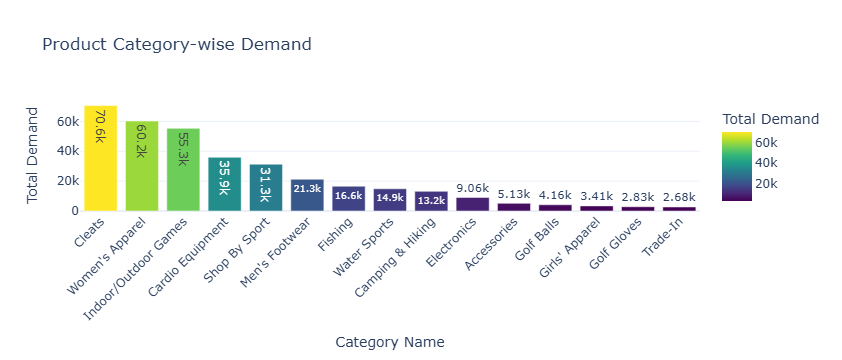

In [25]:
category_demand = (
    df.groupby('Category Name')['Order Item Quantity']
    .sum()
    .reset_index(name='Total Demand')
    .sort_values('Total Demand', ascending=False)
)

category_demand

fig = px.bar(
    category_demand.head(15),
    x='Category Name',
    y='Total Demand',
    color='Total Demand',
    color_continuous_scale='Viridis',
    title='Product Category-wise Demand',
    text_auto='.3s'
)

fig.update_layout(
    template='plotly_white',
    xaxis_tickangle=-45
)

fig.show()

**Observation:**

* Cleats is the highest-demand category with approximately 70.6k units.
* Women's Apparel follows with about 60.2k units.
* Indoor/Outdoor Games ranks third at roughly 55.3k units.
* Demand drops substantially after the top three categories.
* Mid-performing categories include:
    * Cardio Equipment (35.9k)
    * Shop By Sport (31.3k)
    * Men's Footwear (21.3k)
* Lowest-demand categories are:
    * Trade-In (2.68k)
    * Golf Gloves (2.83k)
    * Girls' Apparel (3.41k)
* Demand distribution is highly skewed toward sports-related categories.

**Business Insight:**

* Cleats and Women's Apparel are market leaders and should receive priority inventory replenishment.
* The popularity of sports and fitness-related categories indicates strong customer interest in athletic products.
* Low-performing categories should undergo:
    * Product assortment review
    * Pricing analysis
    * Marketing effectiveness assessment
* Cross-selling opportunities exist between:
    * Cleats and athletic apparel
    * Cardio equipment and accessories
* Inventory planning should be aligned with category demand to reduce stock-outs and excess inventory.

## 3.3 Demand Across Customer Segments

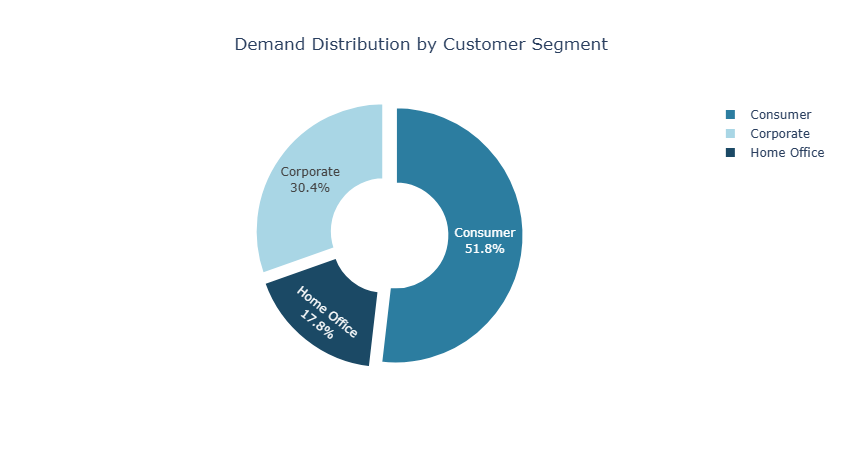

In [24]:
segment_demand = (
    df.groupby('Customer Segment')['Order Item Quantity']
    .sum()
    .reset_index(name='Total Demand')
)

fig = px.pie(
    segment_demand,
    names='Customer Segment',
    values='Total Demand',
    hole=0.4,
    title='Demand Distribution by Customer Segment',
    color='Customer Segment',
    color_discrete_map={
        'Corporate': '#A9D6E5',
        'Consumer': '#2C7DA0',
        'Home Office': '#1B4965'
    }
)

fig.update_traces(
    pull=[0.05, 0.05, 0.05],
    marker=dict(line=dict(color='white', width=3)),
    textinfo='label+percent',
    textposition='inside'
)

fig.update_layout(
    title=dict(x=0.5, xanchor='center'),
    template='plotly_white',
    height=450,
    width=650
)


fig.show()

**Observation:**

* The Consumer segment contributes the largest share of demand:
    * 51.8%
    * Approximately 190,522 units
* The Corporate segment contributes:
    * 30.4%
* The Home Office segment contributes:
    * 17.8%
* Consumer demand is greater than the combined demand of several business-focused segments individually.
* Customer demand is concentrated heavily within the Consumer segment.

**Business Insight:**

* Consumers represent the primary revenue-driving customer base and should remain the core focus of marketing initiatives.
* Corporate customers still represent a significant opportunity, accounting for nearly one-third of total demand.
* The Home Office segment is comparatively smaller but may offer growth opportunities through:
    * Remote working products.
    * Small business packages.
    * Personal productivity equipment.
* Segmented marketing campaigns can improve customer engagement:
    * Consumer: Promotions and seasonal offers.
    * Corporate: Bulk-purchase discounts and contracts.
    * Home Office: Flexible bundles and subscription services.
* Customer retention programmes should prioritise the Consumer segment while designing growth strategies for underpenetrated segments.

## 3.4 Demand vs Sales Analysis

**Objective:** Understand the relationship between product quantity demanded and sales value.

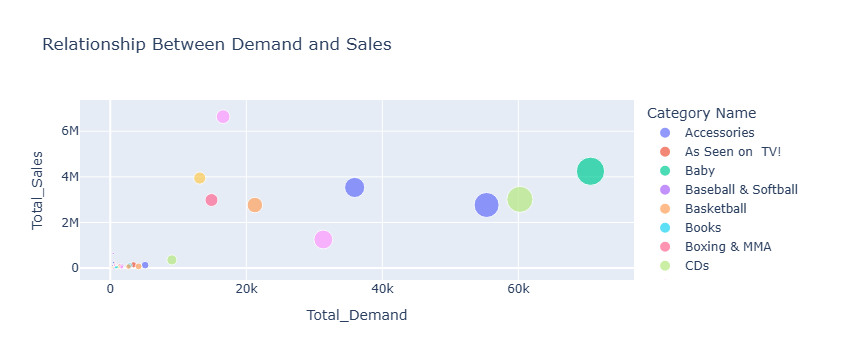

In [143]:
demand_sales = (
    df.groupby('Category Name')
    .agg(
        Total_Demand=('Order Item Quantity', 'sum'),
        Total_Sales=('Sales', 'sum')
    )
    .reset_index()
)

fig = px.scatter(
    demand_sales,
    x='Total_Demand',
    y='Total_Sales',
    color='Category Name',
    size='Total_Demand',
    hover_name='Category Name',
    title='Relationship Between Demand and Sales'
)

fig.show()


**Observation:**

* A few categories dominate both sales and volume, while many categories contribute relatively little revenue.

* The category around 17K units and ~6.6M sales (likely one of the premium categories such as Cameras) generates the highest revenue despite moderate order quantity.

* Categories with 70K+ units sold generate around 4.2M sales, indicating strong demand but lower revenue per unit.

* Cardio Equipment (~36K units, ~3.5M sales) and Camping & Hiking (~13K units, ~3.9M sales) demonstrate strong revenue generation relative to quantity sold.

* Several categories sold fewer than 10K units and generated less than 0.5M sales, indicating limited market impact.

**Business Insight:**

* Categories with high sales but moderate quantities likely have higher margins and higher average selling prices. These products should receive greater marketing and inventory focus.

* Categories with high volume but comparatively lower sales may benefit from upselling, bundling, or premium product introductions to improve revenue per order.

* The business appears to follow a Pareto pattern, where a small number of categories contribute the majority of revenue.

* Inventory planning should prioritise high-demand categories to avoid stockouts while maintaining tighter inventory controls for low-performing categories.

* Categories with low sales and low demand should be reviewed for rationalisation, promotional support, or discontinuation if profitability is weak.

# 4. Correlation Analysis

Correlation analysis helps identify the strength and direction of relationships between numerical variables.

| Correlation | Meaning |
|---|---|
| Close to +1 | Strong positive linear relationship |
| Close to -1 | Strong negative linear relationship |
| Close to 0 | Weak linear relationship |

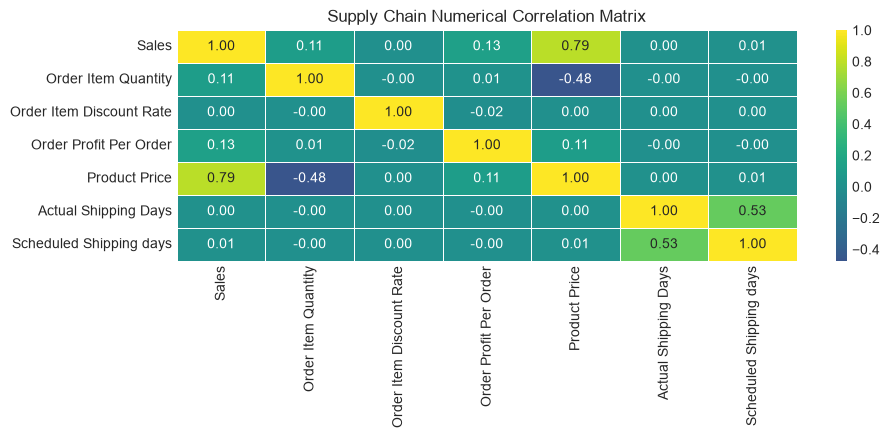

In [38]:
corr_columns = [
    'Sales',
    'Order Item Quantity',
    'Order Item Discount Rate',
    'Order Profit Per Order',
    'Product Price',
    'Actual Shipping Days',
    'Scheduled Shipping days'
]

corr_df = df[corr_columns].corr()
plt.figure(figsize=(10,3))

sns.heatmap(
    corr_df,
    annot=True,
    fmt='.2f',
    cmap='viridis',
    center=0,
    linewidths=0.5
)

plt.title('Supply Chain Numerical Correlation Matrix')

plt.show()

**Observation:**

* Sales and Product Price (0.79): A strong positive correlation exists between Sales and Product Price. This indicates that higher-priced products are generally associated with higher sales values.

* Order Item Quantity and Product Price (-0.48): A moderate negative correlation exists between product price and order quantity. This suggests that higher-priced products tend to have lower quantities ordered, while lower-priced products tend to be purchased in larger quantities.

* Actual Shipping Days and Scheduled Shipping Days (0.53): A moderate positive correlation indicates that orders with longer scheduled shipping durations generally tend to have longer actual shipping durations.

* Sales and Order Profit Per Order (0.13): A very weak positive correlation exists between sales and order profit. Higher sales values do not necessarily translate into proportionally higher profits.

* Sales and Order Item Quantity (0.11): A very weak positive correlation suggests that order quantity has a limited linear relationship with total sales.

* Order Item Discount Rate: The discount rate shows almost zero correlation with sales, order quantity, product price, and order profit. This indicates no meaningful linear relationship between discounts and these numerical variables.

* Shipping Duration and Business Performance: Actual Shipping Days and Scheduled Shipping Days have almost zero correlation with Sales, Order Profit Per Order, and Product Price.

**Business Insight:**


| Area | Business Insight |
|---|---|
| Product Pricing | Product price has a strong relationship with sales value. Pricing strategy plays an important role in overall revenue generation. |
| Customer Purchasing Behaviour | Higher-priced products tend to have lower order quantities, suggesting differences in purchasing behaviour across product price ranges. |
| Shipping Performance | The moderate correlation between actual and scheduled shipping days indicates that scheduled delivery duration is associated with actual delivery duration. |
| Profitability | The weak correlation between sales and profit suggests that generating higher sales does not automatically guarantee higher profitability. |
| Discount Strategy | Discounts do not show a meaningful linear relationship with the other numerical variables. Further analysis is required to understand their impact on sales and profitability. |
| Operational Efficiency | Shipping duration has almost no linear relationship with sales or profit, suggesting that shipping performance and financial performance should be investigated separately. |